In [3]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.7 MB/s eta 0:00:00


In [4]:
import os
import torch
from ultralytics import YOLO
import cv2
import glob
import random
import torch

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [5]:
DATASET_PATH = '/content/drive/MyDrive/floodfinal/flood.v4i.yolov11/data.yaml'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Используется устройство: {device}")

if not os.path.exists(DATASET_PATH):
    print(f"Ошибка: Файл data.yaml не найден по пути: {DATASET_PATH}")
    print("Убедитесь, что вы загрузили папку с датасетом в правильное место.")
else:
    print("Файл конфигурации датасета найден.")


Используется устройство: cuda
Файл конфигурации датасета найден.


In [7]:
model = YOLO('yolo11n.pt').to(device)

print("\nНачинаю обучение модели...")
try:
    results = model.train(
        data=DATASET_PATH,
        epochs=50,
        imgsz=640,
        patience=20,
        device=device,
        verbose=True
    )
    print("Обучение завершено. Лучшая модель сохранена.")
    trained_model_path = os.path.join('runs', 'segment', 'train', 'weights', 'best.pt')
except Exception as e:
    print(f"Произошла ошибка во время обучения: {e}")
    trained_model_path = None


Начинаю обучение модели...
Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/floodfinal/flood.v4i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_ma

In [13]:
if trained_model_path:
    print("\nНачинаю предсказание на 10 случайных тестовых изображениях.")

    trained_model = YOLO("/content/runs/detect/train/weights/best.pt")

    test_images = glob.glob('/content/drive/MyDrive/floodfinal/flood.v4i.yolov11/test/images/*.jpg')

    if not test_images:
        print("Ошибка: Тестовые изображения не найдены в папке test/images.")
    else:
        num_images_to_save = 10
        if len(test_images) < num_images_to_save:
            num_images_to_save = len(test_images)
        selected_images = random.sample(test_images, num_images_to_save)

        output_dir = 'yolo_results_segmentation'
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)

        for i, image_path in enumerate(selected_images):
            print(f"\nОбработка изображения {i+1}/{num_images_to_save}: {image_path}")

            results = trained_model(image_path, conf=0.50, verbose=False)

            result_image = results[0].plot()

            output_image_path = os.path.join(output_dir, f'result_{i+1}_{os.path.basename(image_path)}')
            cv2.imwrite(output_image_path, result_image)

            print(f"Изображение с результатом успешно сохранено по пути: {output_image_path}")

else:
    print("\nОшибка: Не удалось найти обученную модель для предсказания.")
    print("Убедитесь, что обучение прошло без критических ошибок.")


Начинаю предсказание на 10 случайных тестовых изображениях.

Обработка изображения 1/10: /content/drive/MyDrive/floodfinal/flood.v4i.yolov11/test/images/flood-54_jpg.rf.ed406d6193c0f02153b57930d7a8c3b1.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_segmentation/result_1_flood-54_jpg.rf.ed406d6193c0f02153b57930d7a8c3b1.jpg

Обработка изображения 2/10: /content/drive/MyDrive/floodfinal/flood.v4i.yolov11/test/images/flood-12_jpg.rf.be64e78d6a356d17718751b7a4ecc69f.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_segmentation/result_2_flood-12_jpg.rf.be64e78d6a356d17718751b7a4ecc69f.jpg

Обработка изображения 3/10: /content/drive/MyDrive/floodfinal/flood.v4i.yolov11/test/images/images-26-_jpg.rf.84c2875e41e266a3af4f392fce730559.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_segmentation/result_3_images-26-_jpg.rf.84c2875e41e266a3af4f392fce730559.jpg

Обработка изображения 4/10: /content/drive/MyDrive/floodfinal/flood.v4i.y


Полные результаты обучения находятся в файле: runs/detect/train/results.csv

Графики, сгенерированные Ultralytics, находятся в папке: runs/detect/train
Вы можете открыть их в Google Colab.


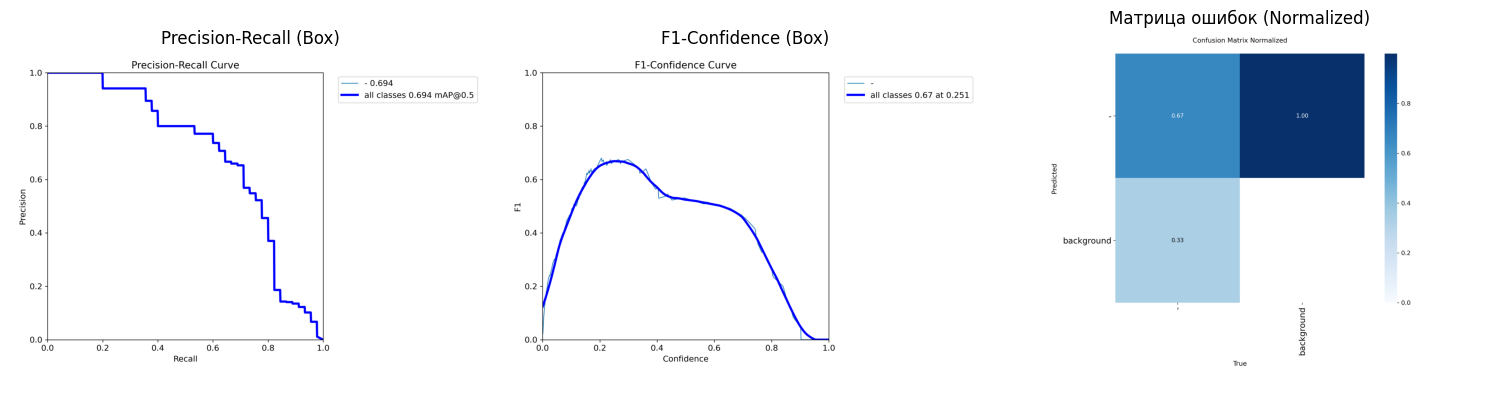

In [18]:
import matplotlib.pyplot as plt

def show_metrics_and_visualizations(run_dir):
    metrics_path = os.path.join(run_dir, 'results.csv')
    if os.path.exists(metrics_path):
        print("\nПолные результаты обучения находятся в файле:", metrics_path)

    print("\nГрафики, сгенерированные Ultralytics, находятся в папке:", run_dir)
    print("Вы можете открыть их в Google Colab.")

    metrics_to_show = {
        'Precision-Recall (Box)': 'BoxPR_curve.png',
        'F1-Confidence (Box)': 'BoxF1_curve.png',
        'Матрица ошибок (Normalized)': 'confusion_matrix_normalized.png'
    }

    plt.figure(figsize=(15, 10))
    for i, (title, filename) in enumerate(metrics_to_show.items()):
        file_path = os.path.join(run_dir, filename)
        if os.path.exists(file_path):
            img = cv2.imread(file_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax = plt.subplot(2, 3, i + 1)
            ax.imshow(img)
            ax.set_title(title)
            ax.axis('off')
        else:
            print(f"Предупреждение: Файл '{filename}' не найден.")

    plt.tight_layout()
    plt.show()

results_dir = os.path.join('runs', 'detect', 'train')
if os.path.exists(results_dir):
    show_metrics_and_visualizations(results_dir)
else:
    print("\nПапка с результатами обучения не найдена. Убедитесь, что обучение завершилось успешно.")

In [16]:
INPUT_IMAGE_DIR = '/content/drive/MyDrive/floodfinal/floodastana'
OUTPUT_IMAGE_DIR = '/content/drive/MyDrive/floodfinal/floodastana_results'

if not os.path.exists(INPUT_IMAGE_DIR):
    print(f"Ошибка: Папка с изображениями '{INPUT_IMAGE_DIR}' не найдена.")
else:
    if not os.path.exists(OUTPUT_IMAGE_DIR):
        os.makedirs(OUTPUT_IMAGE_DIR)
        print(f"Создана папка для результатов: {OUTPUT_IMAGE_DIR}")

    new_images = glob.glob(os.path.join(INPUT_IMAGE_DIR, '*.jpg'))
    new_images.extend(glob.glob(os.path.join(INPUT_IMAGE_DIR, '*.jpeg')))
    new_images.extend(glob.glob(os.path.join(INPUT_IMAGE_DIR, '*.png')))

    if not new_images:
        print(f"В папке '{INPUT_IMAGE_DIR}' не найдено изображений для обработки.")
    else:
        print(f"\nНайдено {len(new_images)} новых изображений для обработки.")

        for i, image_path in enumerate(new_images):
            print(f"\nОбработка изображения {i+1}/{len(new_images)}: {os.path.basename(image_path)}")

            try:
                results = model(image_path, conf=0.25, verbose=False)

                result_image = results[0].plot()

                output_image_path = os.path.join(OUTPUT_IMAGE_DIR, os.path.basename(image_path))
                cv2.imwrite(output_image_path, result_image)

                print(f"Изображение с результатом успешно сохранено по пути: {output_image_path}")

            except Exception as e:
                print(f"Ошибка при обработке изображения {image_path}: {e}")


Найдено 5 новых изображений для обработки.

Обработка изображения 1/5: fa3.jpg
Изображение с результатом успешно сохранено по пути: /content/drive/MyDrive/floodfinal/floodastana_results/fa3.jpg

Обработка изображения 2/5: fa2.jpg
Изображение с результатом успешно сохранено по пути: /content/drive/MyDrive/floodfinal/floodastana_results/fa2.jpg

Обработка изображения 3/5: fa1.jpg
Изображение с результатом успешно сохранено по пути: /content/drive/MyDrive/floodfinal/floodastana_results/fa1.jpg

Обработка изображения 4/5: fa5.jpg
Изображение с результатом успешно сохранено по пути: /content/drive/MyDrive/floodfinal/floodastana_results/fa5.jpg

Обработка изображения 5/5: fa4.jpg
Изображение с результатом успешно сохранено по пути: /content/drive/MyDrive/floodfinal/floodastana_results/fa4.jpg
